In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [4]:
import glob
import os
import kagglehub
import pandas as pd

# 1. Baixa a versão mais recente do dataset do Kaggle
path = kagglehub.dataset_download("alanvourch/tmdb-movies-daily-updates")

# 2. Localiza automaticamente o arquivo .csv dentro da pasta baixada
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Carregando:", csv_path)

# 3. Lê o CSV (low_memory=False evita avisos de tipos mistos em colunas grandes)
df = pd.read_csv(csv_path, low_memory=False)
print(f"Shape: {df.shape}")
df.head()

c:\Users\Aline M\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Carregando: C:\Users\Aline M\.cache\kagglehub\datasets\alanvourch\tmdb-movies-daily-updates\versions\1066\TMDB_all_movies.csv
Shape: (1277547, 30)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10103.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8930.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2933.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Robert Rodriguez, Alexandre Rockwell, Allison ...","Andrzej Sekula, Guillermo Navarro, Rodrigo Gar...","Quentin Tarantino, Allison Anders, Alexandre R...","Quentin Tarantino, Alexandre Rockwell, Lawrenc...",Combustible Edison,6.7,118103.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.6,21502.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [5]:
df.shape

(1277547, 30)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1277547 entries, 0 to 1277546
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1277547 non-null  int64  
 1   title                    1277533 non-null  str    
 2   vote_average             1277547 non-null  float64
 3   vote_count               1277547 non-null  float64
 4   status                   1277547 non-null  str    
 5   release_date             1138806 non-null  str    
 6   revenue                  1277547 non-null  float64
 7   runtime                  1277547 non-null  float64
 8   budget                   1277547 non-null  float64
 9   imdb_id                  701051 non-null   str    
 10  original_language        1277547 non-null  str    
 11  original_title           1277533 non-null  str    
 12  overview                 1079531 non-null  str    
 13  popularity               1277547 non-null  float64
 1

In [7]:
df.describe()

,id,vote_average,vote_count,revenue,runtime,budget,popularity,imdb_rating,imdb_votes
count,1.277547e+06,1.277547e+06,1.277547e+06,1.277547e+06,1.277547e+06,1.277547e+06,1.277547e+06,484634.000000,4.846340e+05
mean,9.185475e+05,2.056151e+00,2.239633e+01,6.708713e+05,4.322073e+01,2.696823e+05,7.516030e-01,6.246781,2.791588e+03
std,5.202328e+05,3.138352e+00,3.702204e+02,1.676849e+07,5.390047e+01,4.792584e+06,1.713279e+00,1.325757,3.268069e+04
min,2.000000e+00,0.000000e+00,0.000000e+00,-1.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,5.000000e+00
25%,4.699565e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,9.810000e-02,5.500000,2.000000e+01
50%,9.083370e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,0.000000e+00,6.000000e-01,6.400000,5.800000e+01
75%,1.374070e+06,5.000000e+00,1.000000e+00,0.000000e+00,8.400000e+01,0.000000e+00,9.130000e-01,7.100000,2.590000e+02
max,1.829007e+06,1.000000e+01,4.190800e+04,2.942650e+09,1.440000e+04,1.000000e+09,5.075043e+02,10.000000,3.265691e+06


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['title', 'release_date', 'imdb_id', 'original_title', 'overview', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']
title                           14
release_date                138741
imdb_id                     576496
original_title                  14
overview                    198016
tagline                    1080401
genres                      336609
production_companies        653706
production_countries        471221
spoken_languages            463210
cast                        400793
director                    203308
director_of_photography     920958
writers                     623958
producers                   829453
music_composer             1125594
imdb_rating                 792913
imdb_votes                  792913
poster_path                

In [10]:
VARS_QUANT = [
    "id",
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity",
    "imdb_rating",
    "imdb_votes"
]

VARS_QUALI = [
    "title",
    "status",
    "release_date",
    "imdb_id",
    "original_language",
    "original_title",
    "overview",
    "tagline",
    "genres",
    "production_companies",
    "production_countries",
    "spoken_languages",
    "cast",
    "director",
    "director_of_photography",
    "writers",
    "producers",
    "music_composer",
    "poster_path",
    "keywords",
    "certification_us"
]

In [11]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
id,918547.49,908337.00,520232.77,2.00,1829007.00,0.02,-1.19
vote_average,2.06,0.00,3.14,0.00,10.00,1.10,-0.35
vote_count,22.40,0.00,370.22,0.00,41908.00,41.61,2422.07
revenue,670871.26,0.00,16768491.17,-12.00,2942649778.00,59.87,5554.82
runtime,43.22,20.00,53.90,0.00,14400.00,44.57,10018.61
budget,269682.32,0.00,4792583.67,0.00,999999999.00,42.88,3636.05
popularity,0.75,0.60,1.71,0.00,507.50,93.40,19955.00
imdb_rating,6.25,6.40,1.33,1.00,10.00,-0.42,0.36
imdb_votes,2791.59,58.00,32680.69,5.00,3265691.00,34.21,1829.89


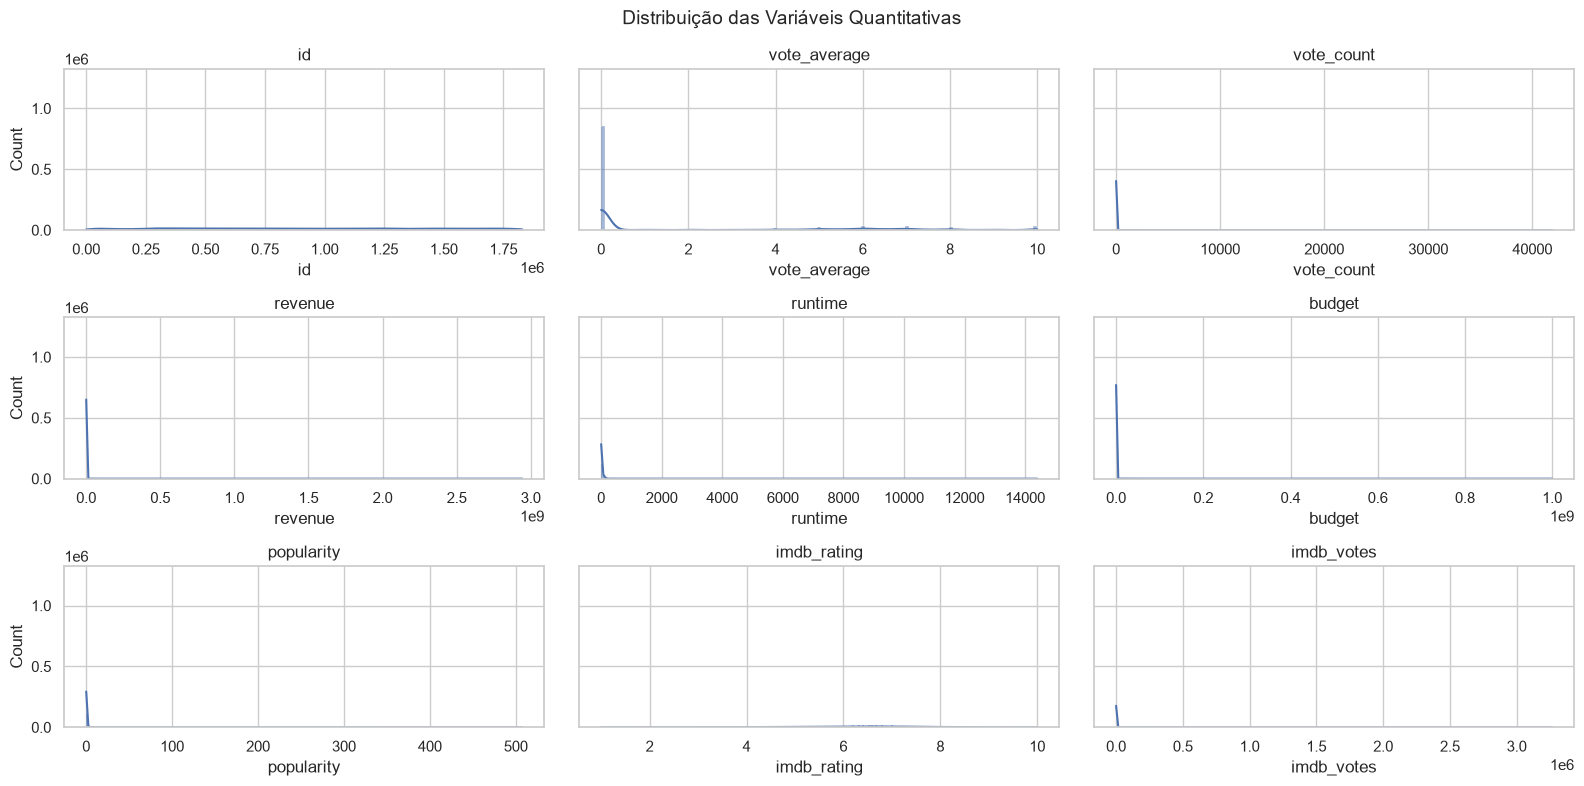

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color="#4C72B0", ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas", fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
id,2.706421e+11,520232.77,904113.00
vote_average,9.850000e+00,3.14,5.00
vote_count,1.370631e+05,370.22,1.00
revenue,2.811823e+14,16768491.17,0.00
runtime,2.905260e+03,53.90,82.00
budget,2.296886e+13,4792583.67,0.00
popularity,2.940000e+00,1.71,0.81
imdb_rating,1.760000e+00,1.33,1.60
imdb_votes,1.068028e+09,32680.69,239.00


In [15]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- title ---
                                                    absoluta  relativa
title                                                                 
Home                                                     208       0.0
Untitled                                                 162       0.0
Mother                                                   136       0.0
Alone                                                    130       0.0
Echo                                                     111       0.0
...                                                      ...       ...
Agent Blue                                                 1       0.0
TRABALHO SÉRIO                                             1       0.0
Monotonous Transformation                                  1       0.0
Fifty Decembers: The Story of the Independence ...         1       0.0
The Cowardly Chandoks                                      1       0.0

[1073140 rows x 2 columns]

--- status ---
                 a

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["rating_out_of_10"]   *********
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

KeyError: 'rating_out_of_10'

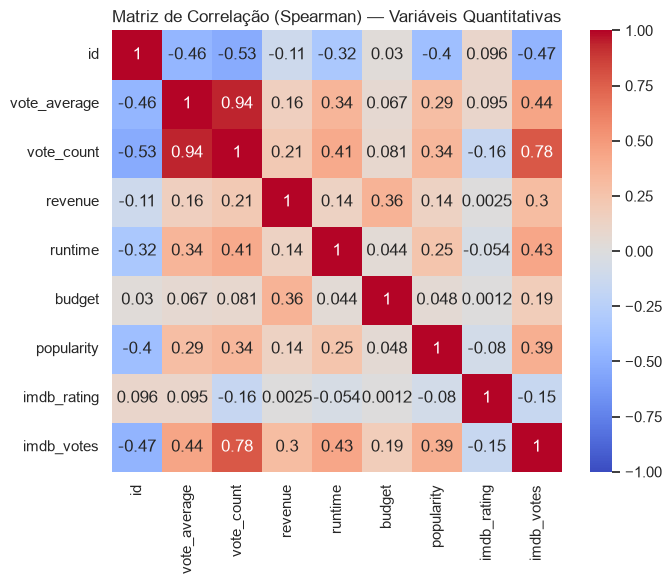

In [17]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="budget_usd", y="box_office_usd", hue="rating_out_of_10",
                palette={"Abaixo de 7": COR_CONTEXTO, "7 ou mais": COR_DESTAQUE}, alpha=0.8) ********
plt.title("budget_usd x box_office_usd")
plt.xlabel("budget_usd")
plt.ylabel("box_office_usd")
plt.tight_layout()
plt.show()

In [18]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
id,-886213.00,2730239.00,0.0
vote_average,-7.50,12.50,0.0
vote_count,-1.50,2.50,221540.0
revenue,0.00,0.00,29304.0
runtime,-121.00,207.00,5440.0
budget,0.00,0.00,87726.0
popularity,-1.12,2.14,69571.0
imdb_rating,3.10,9.50,10705.0
imdb_votes,-338.50,617.50,75438.0


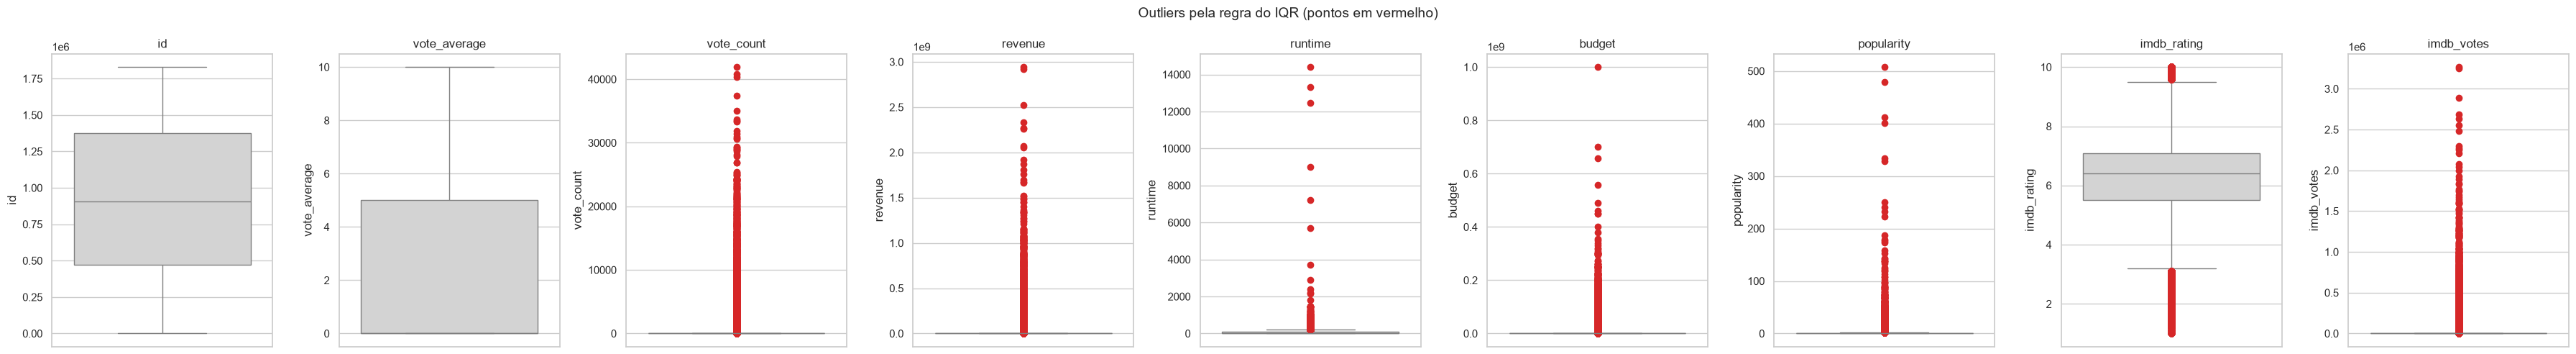

In [19]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

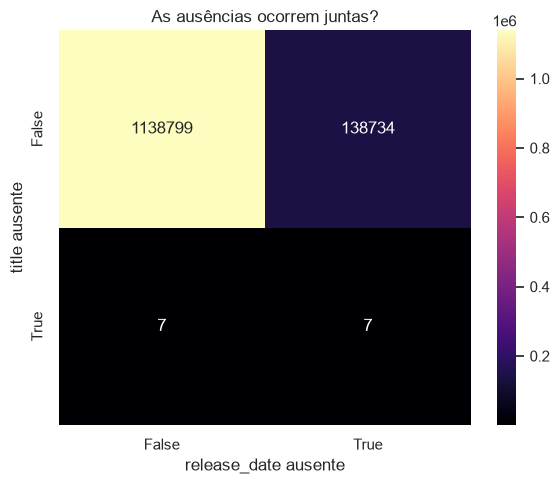

In [20]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()